### Setup

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pathlib as path
from scipy.signal import savgol_filter



In [11]:
# not in globals check lets it not re import all the data every jupter run, much faster
# restart kernal if u want to truely reload the data
if "df" not in globals():
    df = pd.read_csv(
        "CSV/STAG12-24.10.2026-WetEndurance.csv",
        skiprows=14,
        low_memory=False
    )

    units = dict(zip(df.columns, df.iloc[0].tolist()))
    df = df.drop(index=0).reset_index(drop=True)
    df = df.apply(pd.to_numeric, errors="coerce")



# df.head(10)

In [12]:
collumns = df.columns.tolist()
# print(collumns)

In [13]:
suspensiondf = df[[
    # Time and distance
    'Time',
    'Distance',


    # GPS
    'GPS Sats Used',
    'GPS Altitude',
    'GPS Latitude',
    'GPS Longitude',
    'GPS Heading',
    'GPS Time',
    'GPS Date',
    'GPS Speed',



    'WHEEL FL SPEED',
    'WHEEL FR SPEED',
    'WHEEL RL SPEED',
    'WHEEL RR SPEED',

    # Suspension
    'DAMPER FL',
    'DAMPER FR',
    'DAMPER RL',
    'DAMPER RR',
    'Damper Pot FL',
    'Damper Pot FR',
    'Damper Pot RL',
    'Damper Pot RR',

    # Acceleration
    'G Force Lat',
    'G Force Long',
    'G Force Vert',

    # Gyroscope
    'Dash Sensors Gyro X (2)',
    'Dash Sensors Gyro Y (2)',
    'Dash Sensors Gyro Z (2)',

    # Driver inputs
    'VCU APPS',
    'VCU BPS',

    # Aerodynamics
    'VCU DRS Active',
]].copy()

In [14]:
# Convert gps data to xy

# Convert degrees to radians
lat = np.radians(suspensiondf["GPS Latitude"])
lon = np.radians(suspensiondf["GPS Longitude"])

# Reference position
lat0 = lat.iloc[0]
lon0 = lon.iloc[0]

# Convert to metres
R = 6371000

suspensiondf["x"] = R * np.cos(lat0) * (lon - lon0)
suspensiondf["y"] = R * (lat - lat0)

In [15]:
# GPS DATA FILTERING

maxDistance = 500

xMedian = suspensiondf["x"].median()
yMedian = suspensiondf["y"].median()

suspensiondf["distanceFromMedian"] = np.hypot(
    suspensiondf["x"] - xMedian,
    suspensiondf["y"] - yMedian
)

# Identify valid GPS positions
suspensiondf["gpsValid"] = (
    suspensiondf["distanceFromMedian"] < maxDistance
)

# Calculate distance between GPS points
suspensiondf["stepDistance"] = np.hypot(
    suspensiondf["x"].diff(),
    suspensiondf["y"].diff()
)

In [16]:
# LAP START DETECTION

def FindLapStart(suspensiondf, radius=5, minLapTime=15, numCandidates=100):

    gps = suspensiondf.loc[suspensiondf["gpsValid"]].copy()

    x = gps["x"].to_numpy()
    y = gps["y"].to_numpy()
    time = gps["Time"].to_numpy()

    candidates = np.linspace(
        len(gps) // 4,
        3 * len(gps) // 4,
        numCandidates,
        dtype=int
    )

    bestStart = None
    bestScore = -1

    for candidate in candidates:

        distance = np.hypot(
            x - x[candidate],
            y - y[candidate]
        )

        inside = distance < radius

        crossings = np.where(
            inside & ~np.roll(inside, 1)
        )[0]

        crossings = crossings[crossings > 0]

        validCrossings = []

        for crossing in crossings:
            if not validCrossings or time[crossing] - time[validCrossings[-1]] > minLapTime:
                validCrossings.append(crossing)

        if len(validCrossings) < 3:
            continue

        lapTimes = np.diff(time[validCrossings])

        score = len(validCrossings) / (1 + np.std(lapTimes))

        if score > bestScore:
            bestScore = score
            bestStart = candidate

    if bestStart is None:
        raise ValueError("No valid lap start detected")

    return gps.index[bestStart]

In [17]:
# FIND LAPS

radius = 5
minLapTime = 15

suspensiondf = suspensiondf.reset_index(drop=True)

# Find start/finish position
lapStart = FindLapStart(suspensiondf)

xStart = suspensiondf["x"].iloc[lapStart]
yStart = suspensiondf["y"].iloc[lapStart]

# Detect crossings
distance = np.hypot(
    suspensiondf["x"] - xStart,
    suspensiondf["y"] - yStart
)

inside = (distance < radius) & suspensiondf["gpsValid"]

crossings = np.where(
    inside & ~inside.shift(1, fill_value=False)
)[0]

# Remove repeated crossings
validCrossings = []

for crossing in crossings:
    if not validCrossings or suspensiondf["Time"].iloc[crossing] - suspensiondf["Time"].iloc[validCrossings[-1]] > minLapTime:
        validCrossings.append(crossing)

print(f"Detected {len(validCrossings) - 1} complete laps")

Detected 47 complete laps


In [18]:
# UPDATE SUSPENSOIN DF

# Initialise lap column
suspensiondf["Lap"] = 0

# Assign lap numbers
for i in range(len(validCrossings) - 1):

    start = validCrossings[i]
    end = validCrossings[i + 1]

    suspensiondf.loc[start:end-1, "Lap"] = i + 1

print(suspensiondf["Lap"].value_counts().sort_index())

Lap
0     15922
1      5023
2      4790
3      4569
4      4585
5      4476
6      4396
7      4339
8      4368
9      4288
10     4376
11     4437
12     4296
13     4202
14     4302
15     4369
16     4351
17     4414
18     4360
19     4360
20     4337
21     4283
22     4333
23     4393
24    24274
25     4973
26     4441
27     4345
28     4352
29     4376
30     4292
31     4306
32     4366
33     4360
34     4361
35     4327
36     4314
37     4299
38     4236
39     4278
40     4281
41     4276
42     4433
43     4363
44     4750
45     4354
46     4380
47     4395
Name: count, dtype: int64


### damper analysis

In [24]:
damperColumns = [
    "DAMPER FL", "DAMPER FR",
    "DAMPER RL", "DAMPER RR",
    "Damper Pot FL", "Damper Pot FR",
    "Damper Pot RL", "Damper Pot RR"
]

#display(suspensiondf[damperColumns].describe())

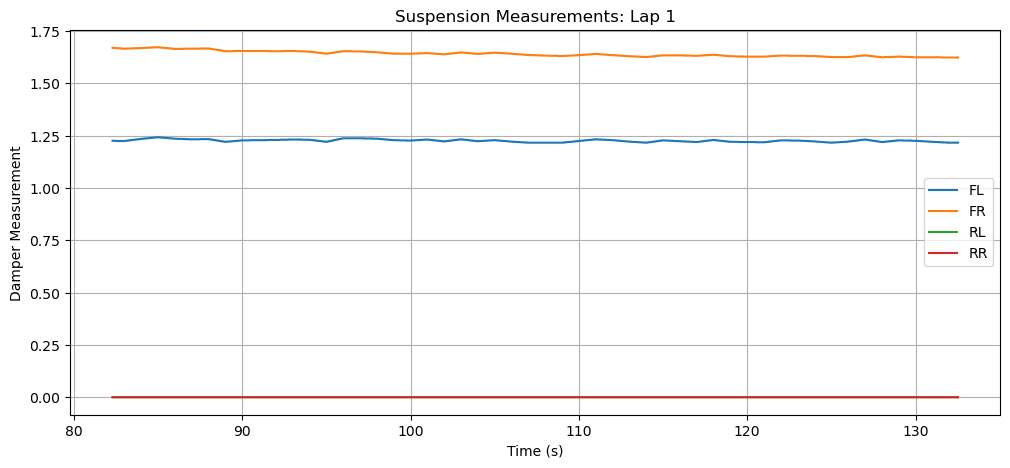

In [25]:
lap = suspensiondf[suspensiondf["Lap"] == 1]

plt.figure(figsize=(12, 5))

for corner in ["FL", "FR", "RL", "RR"]:
    plt.plot(
        lap["Time"],
        lap[f"DAMPER {corner}"],
        label=corner
    )

plt.xlabel("Time (s)")
plt.ylabel("Damper Measurement")
plt.title("Suspension Measurements: Lap 1")
plt.legend()
plt.grid()
plt.show()